# ERDES: first look at the dataset

**Goal:** understand the official metadata before working with videos or models.
Each row describes one ultrasound video clip. These are dataset labels, not model predictions.

Run one code cell at a time with **Shift+Enter** and read its output before continuing.
Use a **CPU runtime**; this notebook needs pandas and matplotlib, with no GPU or PyTorch.
For VS Code/Colab connection steps, see [the notebook guide](README.md).

By the end, we should know the labels, class counts, missing values, and video-length variation.
The notebook downloads only the small metadata CSV. It leaves existing dataset splits untouched.


## 1. Check the runtime and choose storage

The selected kernel runs the code. With a Colab kernel, files below are on Google's machine;
your local project and `.venv` are separate. With a local kernel, we use this project's folders.

The only analysis libraries are **pandas** (tables) and **matplotlib** (plots).
If an import fails, follow the environment instructions in the notebook guide before continuing.


In [2]:
import hashlib
import json
import sys
from datetime import datetime, timezone
from pathlib import Path
from urllib.request import urlopen

import matplotlib
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

cwd = Path.cwd()
project_root = next(
    (p for p in (cwd, *cwd.parents)
     if (p / "pyproject.toml").is_file() and (p / "notebooks").is_dir()),
    None,
)
if project_root is None:
    if not Path("/content").is_dir():
        raise RuntimeError("Open this notebook from the project folder, or select a Colab kernel.")
    project_root = Path("/content")

data_dir = project_root / "data" / "erdes"
output_dir = project_root / "outputs" / "metadata_eda"
data_dir.mkdir(parents=True, exist_ok=True)
output_dir.mkdir(parents=True, exist_ok=True)

print("Python:", sys.version.split()[0])
print("pandas:", pd.__version__)
print("matplotlib:", matplotlib.__version__)
print("Working directory:", cwd)
print("Metadata folder:", data_dir)
print("Results folder:", output_dir)


Python: 3.13.16
pandas: 2.2.3
matplotlib: 3.10.0
Working directory: /content
Metadata folder: /content/data/erdes
Results folder: /content/outputs/metadata_eda


## 2. Load the official metadata

Source: [ERDES on Zenodo, version v1](https://zenodo.org/records/18644370).
The CSV is about 562 kB. We reuse it if already present and verify it against the
checksum published by Zenodo before reading it. A mismatch means **stop and inspect the file**.
No repository clone or video download is needed.


In [3]:
metadata_url = "https://zenodo.org/records/18644370/files/erdes_metadata.csv?download=1"
expected_md5 = "95828fb5bdffdbf8173b5bcfc99e8148"
metadata_path = data_dir / "erdes_metadata.csv"

if not metadata_path.exists():
    with urlopen(metadata_url, timeout=60) as response:
        content = response.read()
    assert hashlib.md5(content).hexdigest() == expected_md5, "Download checksum mismatch; inspect the source."
    metadata_path.write_bytes(content)

metadata_bytes = metadata_path.read_bytes()
assert hashlib.md5(metadata_bytes).hexdigest() == expected_md5, "Cached CSV checksum mismatch; inspect the file."
df = pd.read_csv(metadata_path)
print(f"Loaded {len(df):,} rows and {len(df.columns)} columns from {metadata_path}")
display(df.head())


Loaded 5,381 rows and 10 columns from /content/data/erdes/erdes_metadata.csv


,clip_id,file_path,diagnostic_class,subtype,anatomical_subclass,fps,frame_count,width,height,duration_seconds
0,102769_00001,Retinal_Detachment/Macula_Intact/TD/102769_000...,rd,macula_intact,TD,27.0,140,528,528,5.19
1,102769_00002,Retinal_Detachment/Macula_Intact/TD/102769_000...,rd,macula_intact,TD,27.0,140,528,528,5.19
2,102769_00003,Retinal_Detachment/Macula_Intact/TD/102769_000...,rd,macula_intact,TD,30.0,90,432,432,3.00
3,102769_00004,Retinal_Detachment/Macula_Intact/TD/102769_000...,rd,macula_intact,TD,30.0,90,432,432,3.00
4,102769_00005,Retinal_Detachment/Macula_Intact/TD/102769_000...,rd,macula_intact,TD,30.0,90,432,432,3.00


## 3. Check the metadata

The expected counts below match the release's
[official metadata description](https://zenodo.org/records/18644370/files/erdes_metadata.json?download=1).
Keep these checks: if one fails, investigate instead of changing the expected answer to make it pass.

These checks cover the CSV only. They do not establish that videos are readable, that clips
are independent patients, or that dataset splits avoid leakage.


In [4]:
expected_columns = {
    "clip_id", "file_path", "diagnostic_class", "subtype", "anatomical_subclass",
    "fps", "frame_count", "width", "height", "duration_seconds",
}
assert expected_columns.issubset(df.columns), "Expected metadata columns missing"
assert len(df) == 5381, f"Expected 5,381 clips; found {len(df)}"
assert df["clip_id"].is_unique, "Duplicate clip_id values detected"
assert df["file_path"].is_unique, "Duplicate file_path values detected"
assert not df[["clip_id", "file_path", "diagnostic_class", "subtype"]].isna().any().any()
assert set(df["diagnostic_class"]) == {"rd", "non_rd"}

expected_subtypes = {"normal": 4233, "pvd": 646, "macula_intact": 199, "macula_detached": 303}
assert df["subtype"].value_counts().to_dict() == expected_subtypes, "Unexpected subtype counts"
assert df["diagnostic_class"].value_counts().to_dict() == {"non_rd": 4879, "rd": 502}
rd_subtypes = df["subtype"].isin(["macula_intact", "macula_detached"])
assert (df["diagnostic_class"].eq("rd") == rd_subtypes).all(), "Class/subtype mismatch"

video_columns = ["fps", "frame_count", "width", "height", "duration_seconds"]
assert not df[video_columns].isna().any().any(), "Missing numeric video properties"
assert (df[video_columns] > 0).all().all(), "Non-positive video properties"
print("PASS: release checksum, counts, unique identifiers, labels, and positive video properties")


PASS: release checksum, counts, unique identifiers, labels, and positive video properties


## 4. Understand the table

- `rd`: retinal detachment; subtypes describe whether the macula is intact or detached.
- `non_rd`: normal or `pvd` (posterior vitreous detachment).
- `anatomical_subclass`: a detachment location label, applicable to RD clips only.
  Missing values for non-RD clips are therefore expected.
- `fps`: frames per second; `frame_count`: number of frames; `duration_seconds`: clip length.

Inspect the missing-value table, class counts, and numeric ranges. The clip identifiers
in this CSV do not by themselves establish patient or eye grouping.


In [5]:
display(df.isna().sum().rename("missing_values").to_frame())
class_counts = df["diagnostic_class"].value_counts()
subtype_counts = df["subtype"].value_counts()
display(class_counts.rename("clips").to_frame())
display(subtype_counts.rename("clips").to_frame())
display(df[video_columns].describe().round(2))

always_non_rd_accuracy = float(df["diagnostic_class"].eq("non_rd").mean())
print(f"Always predicting non-RD would give {always_non_rd_accuracy:.2%} accuracy on this CSV.")
print("It would identify 0% of the RD clips. Accuracy alone hides this failure.")
print("This is a label-count calculation, not a trained model or held-out evaluation.")


,missing_values
clip_id,0
file_path,0
diagnostic_class,0
subtype,0
anatomical_subclass,4879
fps,0
frame_count,0
width,0
height,0
duration_seconds,0


,clips
diagnostic_class,
non_rd,4879
rd,502


,clips
subtype,
normal,4233
pvd,646
macula_detached,303
macula_intact,199


,fps,frame_count,width,height,duration_seconds
count,5381.00,5381.00,5381.00,5381.00,5381.00
mean,26.88,92.04,532.57,532.57,3.44
std,6.43,45.90,122.10,122.10,1.60
min,7.04,3.00,272.00,272.00,0.12
25%,25.00,51.00,464.00,464.00,2.11
50%,27.78,90.00,496.00,496.00,3.06
75%,30.00,113.00,496.00,496.00,4.18
max,55.87,638.00,1088.00,1088.00,25.52


Always predicting non-RD would give 90.67% accuracy on this CSV.
It would identify 0% of the RD clips. Accuracy alone hides this failure.
This is a label-count calculation, not a trained model or held-out evaluation.


## 5. Visualize class imbalance and clip lengths

The first plot shows how uneven the subtypes are. The second shows how much clip lengths vary.
We will use these observations when deciding how to sample frames and evaluate a baseline.


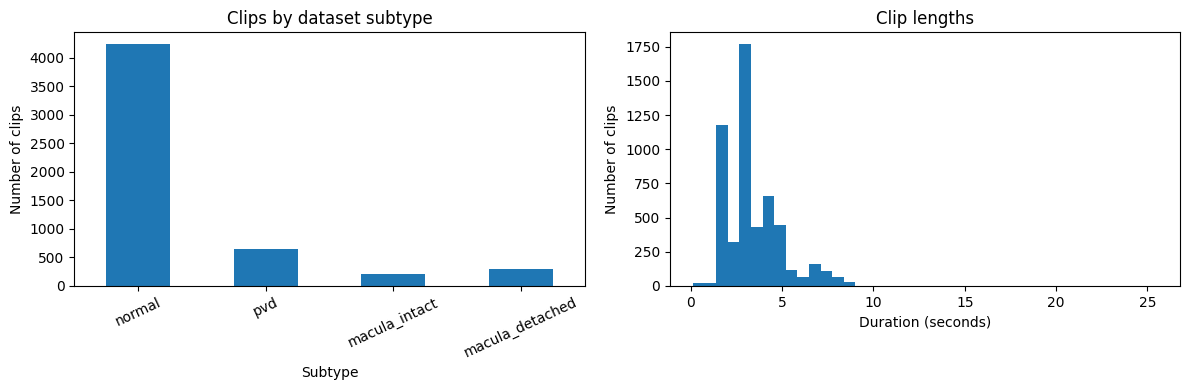

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
subtype_counts.reindex(["normal", "pvd", "macula_intact", "macula_detached"]).plot.bar(ax=axes[0], rot=25)
axes[0].set(title="Clips by dataset subtype", xlabel="Subtype", ylabel="Number of clips")
df["duration_seconds"].plot.hist(ax=axes[1], bins=40)
axes[1].set(title="Clip lengths", xlabel="Duration (seconds)", ylabel="Number of clips")
fig.tight_layout()
fig.savefig(output_dir / "metadata_overview.png", dpi=150)
plt.show()
plt.close(fig)


## 6. Save the evidence

Save the source, checksum, runtime versions, and observed counts alongside the plot.
Local `data/` and `outputs/` folders are ignored by Git. On Colab, download these results
or copy them to Drive before the runtime ends; saving the notebook alone does not save these files.


In [7]:
summary = {
    "recorded_at_utc": datetime.now(timezone.utc).isoformat(),
    "dataset_release": "https://zenodo.org/records/18644370",
    "metadata_url": metadata_url,
    "metadata_md5": expected_md5,
    "metadata_sha256": hashlib.sha256(metadata_bytes).hexdigest(),
    "python": sys.version,
    "pandas": pd.__version__,
    "matplotlib": matplotlib.__version__,
    "clips": len(df),
    "class_counts": {k: int(v) for k, v in class_counts.items()},
    "subtype_counts": {k: int(v) for k, v in subtype_counts.items()},
    "missing_values": {k: int(v) for k, v in df.isna().sum().items()},
    "always_non_rd_accuracy_on_metadata": always_non_rd_accuracy,
    "checks_completed": ["release checksum", "metadata integrity", "metadata exploration"],
    "pending": ["patient/eye grouping and split audit", "video inspection", "baseline design"],
}
summary_path = output_dir / "metadata_summary.json"
summary_path.write_text(json.dumps(summary, indent=2) + "\n", encoding="utf-8")
print("Saved summary:", summary_path)
print("Saved plot:", output_dir / "metadata_overview.png")


Saved summary: /content/outputs/metadata_eda/metadata_summary.json
Saved plot: /content/outputs/metadata_eda/metadata_overview.png


## Stop here and review

Write a few sentences in a new Markdown cell:
1. What labels and class imbalance did you observe?
2. Which missing values are expected, and which would need investigation?
3. What does the range of clip lengths suggest we need to consider later?

**Next session:** inspect the official train/validation/test CSVs, map their entries to this
metadata, check overlap, and investigate whether patient/eye grouping is available.
Keep the supplied splits unchanged while auditing. If grouping is unavailable, record that limitation.
After that, obtain videos following the source's access terms, inspect a few training clips,
and agree on one small baseline and its evaluation plan before selecting training dependencies.

Sources: [dataset release](https://zenodo.org/records/18644370) ·
[authors' code](https://github.com/OSUPCVLab/ERDES) · [paper](https://arxiv.org/abs/2508.04735).
